# Destination choice: letting a block choose plant or waste

**Question:** When is a block's destination part of the scheduling decision, and what value does that flexibility buy?

**Level**: 1

**Prerequisites**: topic 01, CPIT formulation and package setup

**Reading time**: 24 minutes

## Objectives

Build a seeded PCPSP instance with PhaseFlow, run destination-aware scheduling through OreBlocks, and reconcile its value and capacity use. Then distinguish fixed-destination CPIT from joint period-and-destination choice. The notebook's numbers come from fresh computation on the declared synthetic case.

This is a method lesson rather than a report of a baked trace. We rebuild one declared input, call public package methods in sequence, retain their returned arrays, and interpret a figure computed from those results. The exercise separates what the optimization model decides from what a visualization can show. The same cells are useful as a starting point for another small synthetic case, provided its dimensions, scenario, resource rows and destination economics are changed together.

## Setup

From the repository root, install the exact pinned environment. This cell reports the versions actually imported. The notebook never installs packages at runtime.

```bash
pip install oreblocks==0.6.3 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Import the pinned package, plotting tools and PhaseFlow instance builder.
import importlib.metadata as metadata
import json
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks', 'numpy', 'scipy', 'matplotlib'):
    print(package, metadata.version(package))

oreblocks 0.6.3
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Data

The example is the 48-block vein twin generated from seed 31 by PhaseFlow's MIT-licensed instance builder and OreBlocks 0.6.3. The committed twin-vein manifest is read only as provenance context; the schedule is computed from the explicitly reconstructed case. MineLib data are not used: its Newman1 result is an aggregate-only fixed-destination CPIT record under academic-download terms, not redistributable block data or a PCPSP comparator.

Reconstruct the documented teaching case rather than copying its trace into a result. Seed 31 fixes the generated deposit. The manifest at `data/derived/manifests/twin-vein.json` records the committed case's declared context and methods; the block arrays below are built afresh by the pipeline. These sources have different roles: manifest as provenance, seeded generator as experimental input. A deterministic seed supports repeatability, not geological truth. The small case is deliberately used to make destination alternatives and period assignments inspectable. The code below rebuilds exactly the dimensions and scenario stated here; when experimenting, alter the seed explicitly and record every changed capacity or economic assumption.

Build the input through PhaseFlow's typed `Case` and `Scenario` contract. The two resource rows represent mining and processing; their fractions are capacity assumptions, not measured plant limits. We inspect the contract report before passing the instance to the scheduling methods.

In [2]:
# Rebuild the seeded teaching instance and read the committed provenance record.
case = Case(
    id='nb-destination-vein-4x4x3', category='teaching',
    title_en='Destination lesson', title_es='Leccion de destinos',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(periods=4, discount_rate=0.08,
                      capacity_fraction=(0.70, 0.50),
                      resource_names=('mining', 'processing')),
)
instance = build_instance(case)
manifest = json.loads(Path('../../../data/derived/manifests/twin-vein.json').read_text(encoding='utf-8'))
print('contract accepted:', instance.report.ok)
print('blocks:', instance.n_blocks, '| resources:', instance.pcpsp.n_resources,
      '| destinations:', instance.pcpsp.n_destinations)
print('committed provenance case:', manifest['case_id'])

contract accepted: True
blocks: 48 | resources: 2 | destinations: 2
committed provenance case: twin-vein


## Method

A destination-aware model assigns a period and destination together. Each mined block consumes the coefficients for its chosen alternative; each unmined block contributes nothing. The objective discounts the value for the selected destination. The hierarchy of computations below keeps the bound, constructive schedule and score as separate objects, so it is clear which number is an upper bound and which is a feasible result.

The destination-aware model is a different decision problem from CPIT. In CPIT each block has one value and one fixed resource vector before scheduling. In PCPSP the block can be assigned to a destination such as plant or waste, and its value and resource use depend on that choice. A block sent to the plant consumes processing capacity; the same block sent to waste consumes mining capacity but no processing capacity. The schedule must choose both when to extract and where to send each extracted block.

This distinction matters most near capacity limits. A high-grade block may be worth processing, but the plant can be full in the period when its predecessors become available. Sending a marginal block to waste can preserve plant capacity for richer ore. Conversely, a block can wait for a later period if the discounted plant value still exceeds the value of mining it as waste now. Destination choice therefore changes the order, timing and resource coefficients together; it is not a post-processing label added to a CPIT schedule.

PhaseFlow builds a two-destination synthetic instance from the same small seeded vein used in the introductory lesson. The deposit, slope precedence, capacities and grade field are generated by the pinned OreBlocks package through PhaseFlow's instance builder. This case is transparent enough to inspect block counts and resource rows, but it is synthetic evidence. It is not a production design and does not provide field-calibrated destination economics.

We first ask the package for the continuous PCPSP relaxation. Its objective is an upper bound because relaxing binary period and destination choices to fractions enlarges the feasible region. We then run destination-aware TopoSort, which walks a weighted precedence order and selects the best feasible destination and earliest feasible period for each block. The package returns period and destination arrays, the NPV, and period resource use. Recomputing value through the public scorer is a separate reconciliation step, not a second optimizer.

A feasible schedule can be checked period by period. For each resource row, use must not exceed its declared limit. For each precedence arc, a block cannot appear earlier than the prerequisite block. The package constructs resource feasibility while placing blocks, and its schedule scorer rejects a mined block with no valid destination. Those checks establish feasibility for the encoded model; they do not establish optimality, validate the economic assumptions, or prove that a real mine can operate the plan.

Read the result as a comparison of decisions under one declared scenario. The plant/waste counts show how many blocks use each alternative, while the NPV shows their discounted contribution. Neither count alone identifies the economic value of flexibility: a waste assignment may enable a more valuable plant block, and an unmined block contributes no schedule value. The upper bound, feasible result and gap must be interpreted together, with the gap remaining an estimate of distance to the relaxation rather than a certificate of integer optimality.

The plotted period values show where the schedule uses its plant and mining capacity. A bar below a limit means spare capacity in that period, not that increasing capacity would improve the global plan. The graph also omits precedence arcs and geological uncertainty. It is a diagnostic view of one schedule, so the number that matters is accompanied by model inputs, feasibility and the relaxation bound.

The lesson stops at a small two-destination model. PhaseFlow's source cases include published aggregates and synthetic twins, but the published MineLib Newman1 record is a fixed-destination CPIT result and cannot be used as a destination benchmark. Do not compare its objective with this PCPSP objective as if they described the same formulation. The destination paper in References provides research context; this notebook runs PhaseFlow's package implementation on an explicitly synthetic case.

Step 1 computes the continuous PCPSP upper bound. Keep the formulation label beside the value: it bounds a schedule that may choose destinations, not an unrelated CPIT run. The small model fits the direct LP row budget; the status and matrix dimensions are useful checks when scaling the example.

In [3]:
# Solve the PCPSP relaxation to anchor every feasible schedule.
relaxation = ob.pcpsp_lp_bound(instance.pcpsp, instance.precedence,
                                max_rows=1500000, time_limit=20,
                                solution=True)
print('LP status:', relaxation.status)
print('variables:', relaxation.n_variables, '| rows:', relaxation.n_rows)
print('PCPSP upper bound:', round(relaxation.bound, 2))

LP status: optimal
variables: 576 | rows: 1144
PCPSP upper bound: 311484.31


Step 2 constructs a destination-aware plan. The package checks prerequisite availability, then tests the remaining capacity for each destination and period. Its choices are returned as arrays so we can inspect the method's decisions instead of accepting only a headline NPV.

In [4]:
# Build one feasible plan with joint period and destination choices.
destination_plan = ob.destination_toposort(instance.pcpsp,
                                             instance.precedence)
print('method:', destination_plan.method)
print('NPV:', round(destination_plan.npv, 2))
print('mined blocks:', destination_plan.mined_blocks)

method: pcpsp-destination-toposort
NPV: 179593.14
mined blocks: 16


Step 3 independently scores the returned arrays. This is important because a schedule value depends on the chosen destination as well as the period. The capacity matrix is reported by resource and period; comparing it with the declared limits reveals both binding periods and spare capacity.

In [5]:
# Recompute value and resource use from the two decision arrays.
scored_npv, resource_use = ob.pcpsp_schedule_value(
    instance.pcpsp, destination_plan.period_of_block,
    destination_plan.destination_of_block)
plant = int(np.sum(destination_plan.destination_of_block == 1))
waste = int(np.sum(destination_plan.destination_of_block == 0))
print('recomputed NPV:', round(scored_npv, 2))
print('plant blocks:', plant, '| waste blocks:', waste)
print('resource use by period:', np.round(resource_use, 1))
print('resource limits:', np.round(instance.pcpsp.limit, 1))

recomputed NPV: 179593.14
plant blocks: 8 | waste blocks: 8
resource use by period: [[10800. 10800. 10800. 10800.]
 [ 5400.  5400.  5400.  5400.]]
resource limits: [[13230. 13230. 13230. 13230.]
 [ 6075.  6075.  6075.  6075.]]


The chart turns the returned schedules into a period-by-period diagnostic. The horizontal guides are the declared resource limits. Mining and processing remain separate units; counts of blocks are not tonnes. The code uses package-scored resource arrays rather than recomputing coefficients in the notebook.

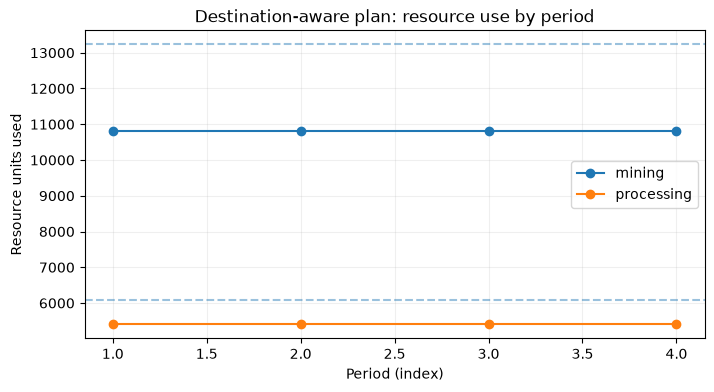

In [6]:
# Plot package-reported capacity use with explicit resource units.
fig, ax = plt.subplots(figsize=(8, 4))
periods = np.arange(1, instance.pcpsp.n_periods + 1)
for resource, label in enumerate(instance.cpit.resource_names):
    ax.plot(periods, resource_use[resource], marker='o', label=label)
    ax.axhline(instance.pcpsp.limit[resource, 0], linestyle='--', alpha=0.45)
ax.set(title='Destination-aware plan: resource use by period',
       xlabel='Period (index)', ylabel='Resource units used')
ax.legend()
ax.grid(alpha=0.2)
plt.show()

The lines show whether the constructed schedule approaches its mining and processing limits in each period; dashed guides mark those declared capacities. A line below its guide indicates unused capacity for this schedule, not proof that relaxing that row has no value. This plot omits block precedence, discounting and destination-specific cash flows, so it is a resource diagnostic rather than a full plan evaluation. The next output reports both destination counts and the independently recomputed objective.

## Results

**Answer:** Destination-aware TopoSort assigns 8 blocks to plant and 8 to waste, with a recomputed NPV of 179593.14; the PCPSP LP relaxation is 311484.31. The value and period-use chart shows how the selected alternatives consume capacity. This is one feasible schedule for a seeded teaching case, not a field plan or an integer-optimality proof.

Use the displayed score and period-use lines to decide whether both the method object and independent scorer agree. The LP objective bounds the same destination-choice model, while the block counts describe assignments rather than tonnes. These outputs are specific to seed 31 and the four-period capacities; they do not transfer to another economic model.

In [7]:
# Keep the computed answer values together for the Results section.
print(f'plant={plant}; waste={waste}; npv={scored_npv:.2f}; bound={relaxation.bound:.2f}')

plant=8; waste=8; npv=179593.14; bound=311484.31


## Summary

Destination choice couples the period decision to the resource and value arrays. The package schedules each block and scores the resulting plan; the relaxation supplies an upper bound for context. The chart describes the declared synthetic case and does not support a universal cutoff or operating recommendation.

## References

- Jelvez, Morales and Nancel-Penard (2018), destination-aware open-pit scheduling: https://www.delphoslab.cl/Publicaciones/2018/Jelvez_et_al_MPES2018.pdf
- PhaseFlow synthetic instance builder and pipeline: https://github.com/fsantibanezleal/CAOS_PhaseFlow
- PhaseFlow dossier: docs/methodologies/09_destinations.md